In [ ]:
import os
import sys

import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from matplotlib.patches import Ellipse

from src.adaptive_clustering import adaptive_clustering

cwd = os.getcwd()
project_dir = os.path.dirname(cwd)
sys.path.insert(0, project_dir)

In [ ]:
N = 100
TOL = 0.1
MIN_PTS_PER_CLUSTER = 100
NUM_INITIAL_CLUSTERS = 1

## Plotters

In [ ]:
# Enable LaTeX rendering
pio.renderers.default = "notebook"


# Plot centroids and surface of the function
def plot_3d_surface_with_centroids(
    X, Z, centroids, func_fn, title: str, Q=None, max_ellipses=100
):
    fig = go.Figure()

    # Add surface
    fig.add_trace(
        go.Surface(
            z=Z.reshape(N, N),
            x=X[:, 0].reshape(N, N),
            y=X[:, 1].reshape(N, N),
            colorscale="Viridis",
            opacity=0.8,
            colorbar=dict(title=r"$f(x_1, x_2)$"),
        )
    )

    # Add centroids
    fig.add_trace(
        go.Scatter3d(
            x=centroids[:, 0],
            y=centroids[:, 1],
            z=func_fn(centroids).flatten(),
            mode="markers",
            marker=dict(size=8, color="red"),
            name="Cluster Centroids",
        )
    )

    # Add trust ellipses projected onto the surface
    if Q is not None:
        # Limit number of ellipses to avoid clutter
        if len(centroids) > max_ellipses:
            np.random.seed(0)
            indices = np.random.choice(len(centroids), max_ellipses, replace=False)
            centroids_subset = centroids[indices]
            Q_subset = Q[indices]
        else:
            centroids_subset = centroids
            Q_subset = Q

        for i in range(len(centroids_subset)):
            mu = centroids_subset[i]
            q_matrix = Q_subset[i]

            # Compute eigenvalues and eigenvectors
            w, V = np.linalg.eig(q_matrix)
            if any(w < 0):
                raise ValueError(
                    f"Negative eigenvalues encountered in Q matrix at centroid {i}. Cannot plot trust ellipse."
                )
            w = np.maximum(w, 1e-10)
            order = np.argsort(w)[::-1]
            w = w[order]
            V = V[:, order]

            # Semi-axes lengths
            a = np.sqrt(1 / w[0])
            b = np.sqrt(1 / w[1])

            # Generate ellipse points in parameter space
            theta = np.linspace(0, 2 * np.pi, 50)
            ellipse_points = np.array([a * np.cos(theta), b * np.sin(theta)]).T

            # Rotate ellipse according to eigenvectors
            rotated_points = ellipse_points @ V.T

            # Translate to centroid position
            ellipse_x = rotated_points[:, 0] + mu[0]
            ellipse_y = rotated_points[:, 1] + mu[1]

            # Evaluate function at ellipse points to get z-coordinates
            ellipse_xy = np.column_stack([ellipse_x, ellipse_y])
            ellipse_z = func_fn(ellipse_xy).flatten()

            # Add ellipse as 3D line trace
            fig.add_trace(
                go.Scatter3d(
                    x=ellipse_x,
                    y=ellipse_y,
                    z=ellipse_z,
                    mode="lines",
                    line=dict(color="red", width=3),
                    showlegend=False,
                    hoverinfo="skip",
                )
            )

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title=r"$x_1$",
            yaxis_title=r"$x_2$",
            zaxis_title=r"$f(x_1, x_2)$",
        ),
        width=1000,
        height=800,
    )

    fig.show()


def plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    title: str,
    plot_trust_ellipses: bool = True,
    max_ellipses: int = 300,
    s: None | float = None,
    n_levels: int = 30,
    plot_log: bool = True,
):
    plt.figure(figsize=(12, 10))
    if plot_log:
        contour = plt.contourf(
            X1,
            X2,
            Z.reshape(N, N),
            levels=n_levels,
            norm=colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
            cmap="viridis",
        )
        plt.colorbar(contour, label=r"$\log_{10}(f(x_1, x_2))$")
    else:
        contour = plt.contourf(
            X1,
            X2,
            Z.reshape(N, N),
            levels=n_levels,
            cmap="viridis",
        )
        plt.colorbar(contour, label=r"$f(x_1, x_2)$")
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$")
    plt.axis("equal")
    plt.title(title)

    # Plot centroids
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        color="k",
        s=s,
        alpha=0.7,
        label="Cluster Centroids",
    )
    if plot_trust_ellipses:
        # Plot elipses representing the trust regions
        if len(centroids) > max_ellipses:
            np.random.seed(0)
            # sample a subset of centroids to avoid clutter
            indices = np.random.choice(len(centroids), max_ellipses, replace=False)
            centroids_subset = centroids[indices]
            Q_subset = Q[indices]
        else:
            centroids_subset = centroids
            Q_subset = Q

        for i in range(len(centroids_subset)):
            mu = centroids_subset[i]
            q_matrix = Q_subset[i]

            w, V = np.linalg.eig(q_matrix)
            if any(w < 0):
                msg = f"Negative eigenvalues encountered in Q matrix at centroid {i}. Skipping ellipse plot for this centroid."
                debug_msg = f"Eigenvalues: {w}, Eigenvectors: {V}, Q matrix: {q_matrix}"
                raise ValueError(msg + "\n" + debug_msg)
            w = np.maximum(w, 1e-10)
            order = np.argsort(w)[::-1]
            w = w[order]
            V = V[:, order]
            a = np.sqrt(1 / w[0])
            b = np.sqrt(1 / w[1])
            angle = np.degrees(np.arctan2(V[1, 0], V[0, 0]))
            ellipse = Ellipse(
                xy=mu,
                width=2 * a,
                height=2 * b,
                angle=angle,
                edgecolor="red",
                facecolor="none",
                lw=1,
                alpha=0.5,
            )
            plt.gca().add_patch(ellipse)

    # Restrict axes to the data range
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    plt.legend()
    plt.show()

# Goldstein Price Function

In [ ]:
def goldstein_price_2d(X):
    """
    Compute the 2D Goldstein-Price function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = 1 + (x1 + x2 + 1) ** 2 * (
        19 - 14 * x1 + 3 * x1**2 - 14 * x2 + 6 * x1 * x2 + 3 * x2**2
    )
    term2 = 30 + (2 * x1 - 3 * x2) ** 2 * (
        18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2
    )
    res = term1 * term2
    return res[:, np.newaxis]


def grad_goldstein_price_2d(X):
    """
    Compute the gradient of the 2D Goldstein-Price function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]

    # Partial derivatives
    dfdx1 = (
        2
        * (x1 + x2 + 1)
        * (19 - 14 * x1 + 3 * x1**2 - 14 * x2 + 6 * x1 * x2 + 3 * x2**2)
        + (1 + (x1 + x2 + 1) ** 2) * (-14 + 6 * x1 + 6 * x2)
    ) * (
        30
        + (2 * x1 - 3 * x2) ** 2
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
    ) + (1 + (x1 + x2 + 1) ** 2) * (
        2
        * (2 * x1 - 3 * x2)
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
        + (2 * x1 - 3 * x2) ** 2 * (-32 + 24 * x1 - 36 * x2)
    )

    dfdx2 = (
        2
        * (x1 + x2 + 1)
        * (19 - 14 * x1 + 3 * x1**2 - 14 * x2 + 6 * x1 * x2 + 3 * x2**2)
        + (1 + (x1 + x2 + 1) ** 2) * (-14 + 6 * x1 + 6 * x2)
    ) * (
        30
        + (2 * x1 - 3 * x2) ** 2
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
    ) + (1 + (x1 + x2 + 1) ** 2) * (
        2
        * (2 * x1 - 3 * x2)
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
        + (2 * x1 - 3 * x2) ** 2 * (48 - 36 * x1 + 54 * x2)
    )
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-4, 4, N)
x2 = np.linspace(-4, 4, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = goldstein_price_2d(X)

In [ ]:
_m = MIN_PTS_PER_CLUSTER
results = adaptive_clustering(
    X=X,
    f_fn=goldstein_price_2d,
    g_fn=grad_goldstein_price_2d,
    TOL=TOL / 10,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=_m,
    SYNTH_BUDGET_FACTOR=50 * 50,
    ERROR_SCALING_METHOD="global",
    Q_SHRINK=0,
)
centroids = results["centroids"]
Q = results["Q"]
print(f"float(np.max(np.linalg.cond(Q))) = {float(np.max(np.linalg.cond(Q))):,}")

float(np.max(np.linalg.cond(Q))) = 155,476.45254085195


float(np.max(np.linalg.cond(Q))) = 155,476.45254085195


/home/prajwal/github-repos/knnsur/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



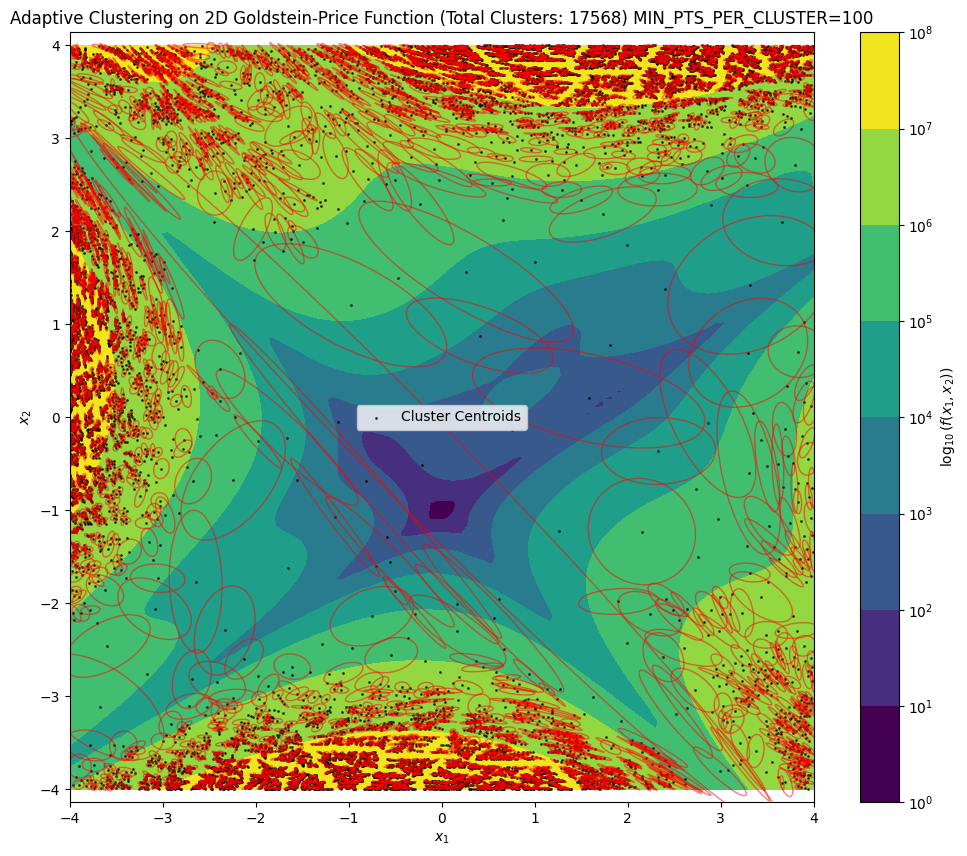

In [ ]:
_m = MIN_PTS_PER_CLUSTER
results = adaptive_clustering(
    X=X,
    f_fn=goldstein_price_2d,
    g_fn=grad_goldstein_price_2d,
    TOL=TOL / 10,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=_m,
    SYNTH_BUDGET_FACTOR=50 * 50,
    ERROR_SCALING_METHOD="global",
    Q_SHRINK=0,
)
centroids = results["centroids"]
Q = results["Q"]
print(f"float(np.max(np.linalg.cond(Q))) = {float(np.max(np.linalg.cond(Q))):,}")


plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
    plot_trust_ellipses=True,
    max_ellipses=10000,
    s=1.0,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     goldstein_price_2d,
#     f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
#     Q=Q,
#     max_ellipses=1000,
# )

float(np.max(np.linalg.cond(Q))) = 18.99768481975442


/home/prajwal/github-repos/knnsur/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



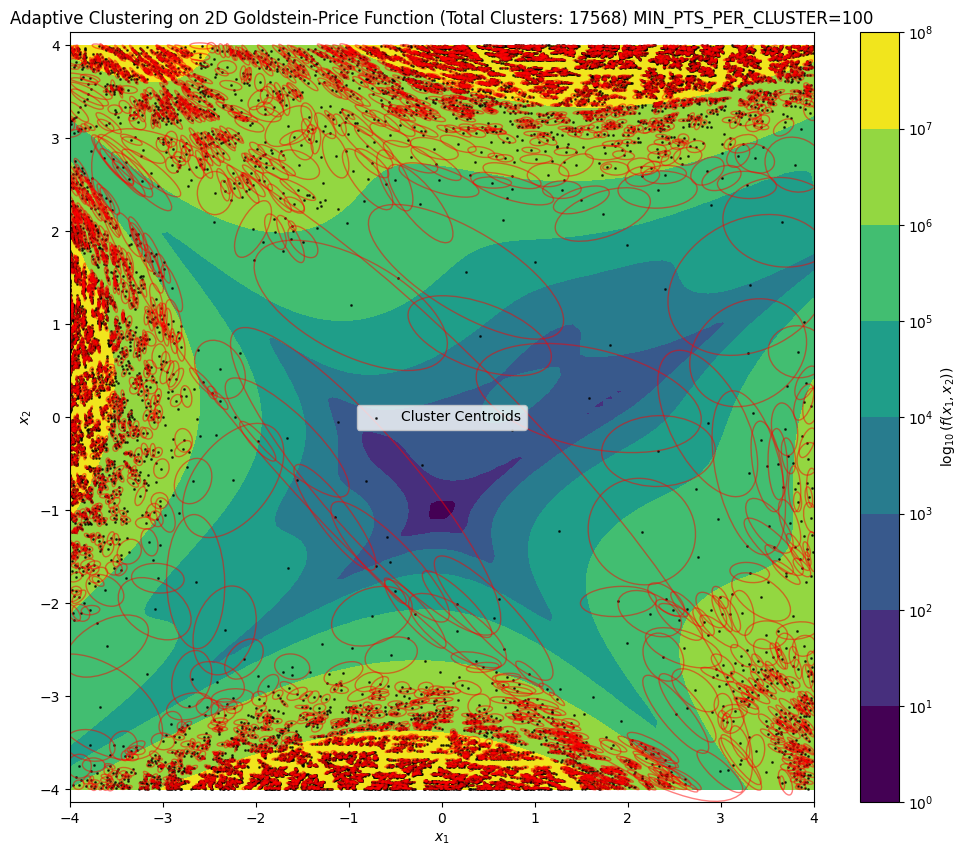

In [13]:
_m = MIN_PTS_PER_CLUSTER
results = adaptive_clustering(
    X=X,
    f_fn=goldstein_price_2d,
    g_fn=grad_goldstein_price_2d,
    TOL=TOL / 10,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=_m,
    SYNTH_BUDGET_FACTOR=50 * 50,
    ERROR_SCALING_METHOD="global",
    Q_SHRINK=0.1,
)
centroids = results["centroids"]
Q = results["Q"]
print(f"float(np.max(np.linalg.cond(Q))) = {float(np.max(np.linalg.cond(Q))):,}")


plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
    plot_trust_ellipses=True,
    max_ellipses=10000,
    s=1.0,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     goldstein_price_2d,
#     f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
#     Q=Q,
#     max_ellipses=1000,
# )

## Rosenbrock Function 

In [ ]:
R_SCALE = 1


def rosenbrock_2d(X):
    """
    Compute the 2D Rosenbrock function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    res = (1 - x1) ** 2 + R_SCALE * (x2 - x1**2) ** 2
    return res[:, np.newaxis]


def grad_rosenbrock_2d(X):
    """
    Compute the gradient of the 2D Rosenbrock function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = -2 * (1 - x1) - 4 * R_SCALE * x1 * (x2 - x1**2)
    dfdx2 = 2 * R_SCALE * (x2 - x1**2)
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-4, 4, N)
x2 = np.linspace(-4, 4, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
print(f"Number of points: {X.shape[0]:,}")
Z = rosenbrock_2d(X)

results = adaptive_clustering(
    X=X,
    f_fn=rosenbrock_2d,
    g_fn=grad_rosenbrock_2d,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=MIN_PTS_PER_CLUSTER,
    SYNTH_BUDGET_FACTOR=10,
)

centroids = results["centroids"]
Q = results["Q"]

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Rosenbrock Function (Total Clusters: {len(centroids)})",
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     rosenbrock_2d,
#     f"Adaptive Clustering on 2D Rosenbrock Function (Total Clusters: {len(centroids)})",
#     Q=Q,
#     max_ellipses=500,
# )

## Beale Function

In [ ]:
def beale_2d(X):
    """
    Compute the 2D Beale function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = (1.5 - x1 + x1 * x2) ** 2
    term2 = (2.25 - x1 + x1 * x2**2) ** 2
    term3 = (2.625 - x1 + x1 * x2**3) ** 2
    res = term1 + term2 + term3
    return res[:, np.newaxis]


def grad_beale_2d(X):
    """
    Compute the gradient of the 2D Beale function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = (
        2 * (1.5 - x1 + x1 * x2) * (-1 + x2)
        + 2 * (2.25 - x1 + x1 * x2**2) * (-1 + x2**2)
        + 2 * (2.625 - x1 + x1 * x2**3) * (-1 + x2**3)
    )
    dfdx2 = (
        2 * (1.5 - x1 + x1 * x2) * (x1)
        + 4 * (2.25 - x1 + x1 * x2**2) * (x1 * x2)
        + 6 * (2.625 - x1 + x1 * x2**3) * (x1 * x2**2)
    )
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-4.5, 4.5, N)
x2 = np.linspace(-4.5, 4.5, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
print(f"Number of points: {X.shape[0]:,}")
Z = beale_2d(X)

results = adaptive_clustering(
    X=X,
    f_fn=beale_2d,
    g_fn=grad_beale_2d,
    TOL=TOL / 10,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=MIN_PTS_PER_CLUSTER,
    SYNTH_BUDGET_FACTOR=10,
)
centroids = results["centroids"]
Q = results["Q"]

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Beale Function (Total Clusters: {len(centroids)})",
    plot_trust_ellipses=True,
    plot_log=True,
    n_levels=200,
    max_ellipses=2000,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     beale_2d,
#     f"Adaptive Clustering on 2D Beale Function (Total Clusters: {len(centroids)})",
#     Q=Q,
#     max_ellipses=1000,
# )

## Ackley Function

In [ ]:
def ackley_2d(X):
    """
    Compute the 2D Ackley function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = -20 * np.exp(-0.2 * np.sqrt(0.5 * (x1**2 + x2**2)))
    term2 = -np.exp(0.5 * (np.cos(2 * np.pi * x1) + np.cos(2 * np.pi * x2)))
    res = term1 + term2 + 20 + np.e
    return res[:, np.newaxis]


def grad_ackley_2d(X):
    """
    Compute the gradient of the 2D Ackley function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    a = 20
    b = 0.2
    c = 2 * np.pi

    sum_sq = x1**2 + x2**2
    term1 = (a * b / np.sqrt(0.5 * sum_sq)) * np.exp(-b * np.sqrt(0.5 * sum_sq))
    dfdx1 = term1 * x1 + (c / 2) * np.sin(c * x1) * np.exp(
        0.5 * (np.cos(c * x1) + np.cos(c * x2))
    )
    dfdx2 = term1 * x2 + (c / 2) * np.sin(c * x2) * np.exp(
        0.5 * (np.cos(c * x1) + np.cos(c * x2))
    )

    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-5, 5, N)
x2 = np.linspace(-5, 5, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
print(f"Number of points: {X.shape[0]:,}")
Z = ackley_2d(X)

results = adaptive_clustering(
    X=X,
    f_fn=ackley_2d,
    g_fn=grad_ackley_2d,
    TOL=TOL,
    MIN_PTS_PER_CLUSTER=MIN_PTS_PER_CLUSTER,
    SYNTH_BUDGET_FACTOR=100,
)
centroids = results["centroids"]
Q = results["Q"]

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Ackley Function (Total Clusters: {len(centroids)})",
    plot_trust_ellipses=True,
    plot_log=False,
    n_levels=100,
    s=1,
    max_ellipses=900,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     ackley_2d,
#     f"Adaptive Clustering on 2D Ackley Function (Total Clusters: {len(centroids)})",
#     Q=Q,
#     max_ellipses=1000,
# )

## Goldstein-Price Function

In [ ]:
_m = MIN_PTS_PER_CLUSTER
results = adaptive_clustering(
    X=X,
    f_fn=goldstein_price_2d,
    g_fn=grad_goldstein_price_2d,
    TOL=TOL / 10,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=_m,
    SYNTH_BUDGET_FACTOR=50 * 50,
    ERROR_SCALING_METHOD="global",
    COVZ_SHRINK=-0.2,
    Q_SHRINK=-0.2,
)
centroids = results["centroids"]
Q = results["Q"]


plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
    plot_trust_ellipses=True,
    max_ellipses=10000,
    s=1.0,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     goldstein_price_2d,
#     f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
#     Q=Q,
#     max_ellipses=1000,
# )

In [ ]:
_m = MIN_PTS_PER_CLUSTER
results = adaptive_clustering(
    X=X,
    f_fn=goldstein_price_2d,
    g_fn=grad_goldstein_price_2d,
    TOL=TOL / 10,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=_m,
    SYNTH_BUDGET_FACTOR=50 * 50,
    ERROR_SCALING_METHOD="global",
)
centroids = results["centroids"]
Q = results["Q"]


plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
    plot_trust_ellipses=True,
    max_ellipses=1000,
    s=1.0,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     goldstein_price_2d,
#     f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
#     Q=Q,
#     max_ellipses=1000,
# )

In [ ]:
_m = MIN_PTS_PER_CLUSTER
results = adaptive_clustering(
    X=X,
    f_fn=goldstein_price_2d,
    g_fn=grad_goldstein_price_2d,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=_m,
    SYNTH_BUDGET_FACTOR=50 * 50,
    ERROR_SCALING_METHOD="local",
)
centroids = results["centroids"]
Q = results["Q"]

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
    plot_trust_ellipses=True,
    max_ellipses=10_000,
    s=1.0,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     goldstein_price_2d,
#     f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(centroids)}) MIN_PTS_PER_CLUSTER={_m}",
#     Q=Q,
#     max_ellipses=1000,
# )

## Himmelblau's Function

In [ ]:
def himmelblau_2d(X):
    """
    Compute the 2D Himmelblau's function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = (x1**2 + x2 - 11) ** 2
    term2 = (x1 + x2**2 - 7) ** 2
    res = term1 + term2
    return res[:, np.newaxis]


def grad_himmelblau_2d(X):
    """
    Compute the gradient of the 2D Himmelblau's function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = 4 * (x1**2 + x2 - 11) * x1 + 2 * (x1 + x2**2 - 7)
    dfdx2 = 2 * (x1**2 + x2 - 11) + 4 * (x1 + x2**2 - 7) * x2
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-5, 5, N)
x2 = np.linspace(-5, 5, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = himmelblau_2d(X)

results = adaptive_clustering(
    X=X,
    f_fn=himmelblau_2d,
    g_fn=grad_himmelblau_2d,
    TOL=TOL * 1,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=MIN_PTS_PER_CLUSTER,
    SYNTH_BUDGET_FACTOR=100,
    ERROR_SCALING_METHOD="local",
)
centroids = results["centroids"]
Q = results["Q"]

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Himmelblau's Function (Total Clusters: {len(centroids)})",
    plot_trust_ellipses=True,
    max_ellipses=5000,
    plot_log=True,
    n_levels=200,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     himmelblau_2d,
#     f"Adaptive Clustering on 2D Himmelblau's Function (Total Clusters: {len(centroids)})",
#     Q=Q,
#     max_ellipses=1000,
# )

## Rastrigin Function

In [ ]:
def rastrigin_2d(X):
    """
    Compute the 2D Rastrigin function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    A = 10
    res = (
        A * 2
        + (x1**2 - A * np.cos(2 * np.pi * x1))
        + (x2**2 - A * np.cos(2 * np.pi * x2))
    )
    return res[:, np.newaxis]


def grad_rastrigin_2d(X):
    """
    Compute the gradient of the 2D Rastrigin function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    A = 10
    dfdx1 = 2 * x1 + 2 * np.pi * A * np.sin(2 * np.pi * x1)
    dfdx2 = 2 * x2 + 2 * np.pi * A * np.sin(2 * np.pi * x2)
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-5.12, 5.12, N)
x2 = np.linspace(-5.12, 5.12, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = rastrigin_2d(X)

results = adaptive_clustering(
    X=X,
    f_fn=rastrigin_2d,
    g_fn=grad_rastrigin_2d,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=NUM_INITIAL_CLUSTERS,
    MIN_PTS_PER_CLUSTER=MIN_PTS_PER_CLUSTER,
    SYNTH_BUDGET_FACTOR=200,
)
centroids = results["centroids"]
Q = results["Q"]

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    Q,
    f"Adaptive Clustering on 2D Rastrigin Function (Total Clusters: {len(centroids)})",
    plot_trust_ellipses=True,
    max_ellipses=2000,
    plot_log=False,
    s=1,
)

# plot_3d_surface_with_centroids(
#     X,
#     Z,
#     centroids,
#     rastrigin_2d,
#     f"Adaptive Clustering on 2D Rastrigin Function (Total Clusters: {len(centroids)})",
#     Q=Q,
#     max_ellipses=1000,
# )